In [2]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy import stats

# Problem 4



In [3]:
df = pd.read_csv("ALE_data.csv")

X = df[["anchor_ratio", "trans_range", "node_density", "iterations"]]
y = df["ale"]

In [4]:
models = {
    "Linear regression": LinearRegression(),
    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=1.0, epsilon=0.01)
    ),
    "Decision tree": DecisionTreeRegressor(
        max_depth=3, random_state=42
    )
}

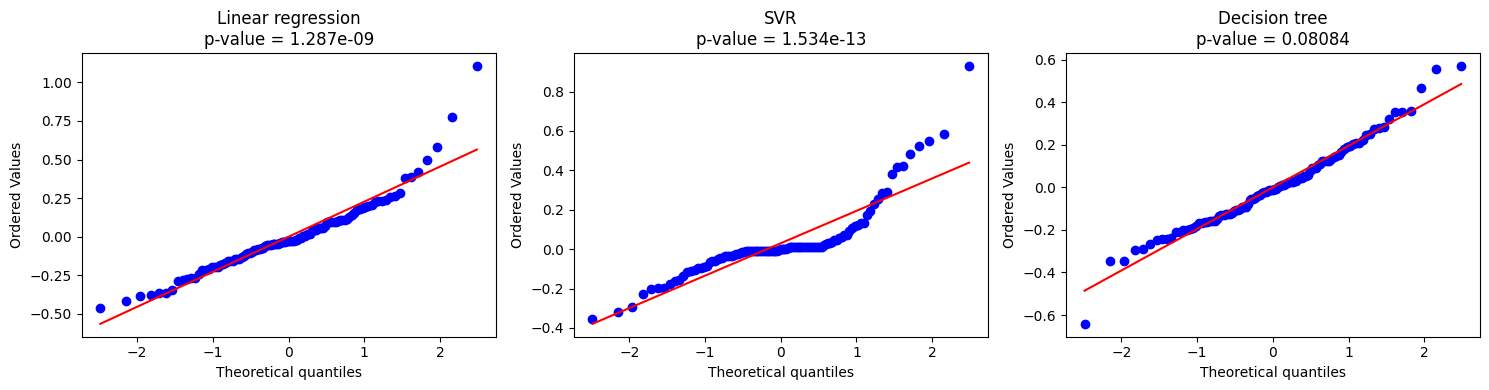

            Model  Normality statistic      p-value  Reject normality (0.05)
Linear regression            40.942406 1.286677e-09                     True
              SVR            59.011238 1.534166e-13                     True
    Decision tree             5.030581 8.083943e-02                    False


In [5]:
results = []

fig, axes = plt.subplots(
    1, len(models), figsize=(15, 4)
)

for ax, (name, model) in zip(axes, models.items()):
  model.fit(X, y)
  predictions = model.predict(X)

  residuals = y.to_numpy() - predictions

  statistic, p_value = stats.normaltest(residuals)

  results.append({
      "Model": name,
      "Normality statistic": statistic,
      "p-value": p_value,
      "Reject normality (0.05)": p_value < 0.05
  })

  stats.probplot(residuals, dist="norm", plot=ax)
  ax.set_title(f"{name}\np-value = {p_value:.4g}")

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

I fitted three regression models--Linear Regression, SVR, and Decision Tree--to predict ALE using the first four variables. I then applied the normality test to the residuals of each model.

At the 0.05 significance level, I rejected the null hypothesis of normality for Linear Regression and SVR (p < 0.05), suggesting that their residuals are not normally distributed. In contrast, I failed to reject the null hypothesis for Decision Tree, indicating insufficient evidence to conclude that its residuals deviate from a normal distribution.

Overall, among the three models, only Decision Tree did not show a statistically significant deviation from residual normality.

# Problem 5

## **Classification**

In [6]:
import torch
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from torch import nn
from torch.utils.data import TensorDataset, DataLoader


SEED = 1250

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Baseline sklearn logistic regression

In [7]:
baseline = LogisticRegression(max_iter=5000)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_acc = accuracy_score(y_test, baseline_pred)

print(f"sklearn logistic accuracy: {baseline_acc:.4f}")

sklearn logistic accuracy: 0.9825


### Define functions

In [8]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)

In [9]:
class BinaryRegression(nn.Module):
  def __init__(self, n_features, link):
    super().__init__()
    self.linear = nn.Linear(n_features, 1)
    self.link = link
    nn.init.zeros_(self.linear.weight)
    nn.init.zeros_(self.linear.bias)

  def forward(self, x):
    z = self.linear(x).squeeze(-1)
    if self.link == "logistic":
      return torch.sigmoid(z)
    if self.link == "probit":
      standard_normal = torch.distributions.Normal(0.0, 1.0)
      return standard_normal.cdf(z)

def binary_cross_entropy(y, p):
  p = torch.clamp(p, min=1e-6, max=1 - 1e-6)
  loss = -(y * torch.log(p) + (1-y) * torch.log(1-p))
  return loss.mean()

def train_model(link, epochs=300, learning_rate=0.01):
  model = BinaryRegression(
      n_features=X_train_t.shape[1],
      link=link,
  )

  optimizer = torch.optim.SGD(
      model.parameters(),
      lr=learning_rate,
  )

  generator = torch.Generator().manual_seed(SEED)
  loader = DataLoader(
      train_dataset, batch_size=32,
      shuffle=True, generator=generator,
  )

  model.train()

  for epoch in range(epochs):
    total_loss = 0.0

    for xb, yb in loader:
      optimizer.zero_grad()

      probabilities = model(xb)
      loss = binary_cross_entropy(yb, probabilities)

      loss.backward()
      optimizer.step()

      total_loss += loss.item() * len(yb)

  return model

In [10]:
def evaluate_model(model):
  model.eval()

  with torch.no_grad():
    probabilities = model(X_test_t)
    predictions = (probabilities >= 0.5).float()
    accuracy = (predictions == y_test_t).float().mean().item()

  return accuracy

### (a) Pytorch Logistic Regression


In [11]:
logistic_model = train_model("logistic")
logistic_acc = evaluate_model(logistic_model)

print("\nTest accuracy")
print(f"sklearn logistic: {baseline_acc:.4f}")
print(f"Pytorch logistic: {logistic_acc:.4f}")


Test accuracy
sklearn logistic: 0.9825
Pytorch logistic: 0.9737


The Pytorch logistic regression model achieved a test accuracy of 97.37%, compared with 98.25% for the scikit-learn baseline. On the 114 test samples, these results correspond to 111 and 112 correct predictions, respectively. Thus, the Pytorch implementation performed comparably to the baseline.

### (b) Pytorch Probit Regression

In [12]:
probit_model = train_model("probit")
probit_acc = evaluate_model(probit_model)

print("\nTest accuracy")
print(f"sklearn logistic: {baseline_acc:.4f}")
print(f"Pytorch probit  : {probit_acc:.4f}")


Test accuracy
sklearn logistic: 0.9825
Pytorch probit  : 0.9825


The Pytorch probit model also achieved 98.25% accuracy, matching the baseline on this test split.

## **Regression**

In [13]:
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("ALE_data.csv")
X = df[["anchor_ratio", "trans_range", "node_density", "iterations"]]
y = df["ale"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

baseline = LinearRegression()
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_mae = mean_absolute_error(y_test, baseline_pred)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)

### Define functions

In [14]:
class LinearRegressionModel(nn.Module):
  def __init__(self, n_features):
    super().__init__()
    self.linear = nn.Linear(n_features, 1)
    nn.init.zeros_(self.linear.weight)
    nn.init.zeros_(self.linear.bias)

  def forward(self, x):
    return self.linear(x).squeeze(-1)

def mse_loss(y, predictions):
  return ((y - predictions) ** 2).mean()

def student_t_loss(y, predictions):
  residuals = y - predictions
  distribution = torch.distributions.StudentT(
      df=5.0, loc=0.0, scale=1.0
  )
  return -distribution.log_prob(residuals).mean()

In [15]:
def train_regression_model(loss_name, epochs=1000, learning_rate=0.01):
  model = LinearRegressionModel(n_features=X_train_t.shape[1])

  optimizer = torch.optim.SGD(
      model.parameters(),
      lr=learning_rate,
  )

  generator = torch.Generator().manual_seed(SEED)
  loader = DataLoader(
      train_dataset, batch_size=32,
      shuffle=True, generator=generator,
  )

  if loss_name == "mse":
    loss_function = mse_loss
  if loss_name == "student_t":
    loss_function = student_t_loss

  model.train()

  for epoch in range(epochs):
    total_loss=0.0

    for xb, yb in loader:
      optimizer.zero_grad()

      predictions = model(xb)
      loss = loss_function(yb, predictions)

      loss.backward()
      optimizer.step()

      total_loss += loss.item() * len(yb)

  return(model)

In [16]:
def evaluate_regression_model(model):
  model.eval()

  with torch.no_grad():
    predictions = model(X_test_t)
    mae = torch.abs(y_test_t - predictions).mean().item()

  return mae

### (a) MSE

In [17]:
mse_model = train_regression_model("mse")
mse_mae = evaluate_regression_model(mse_model)

print("\nTest MAE")
print(f"sklearn linear regression: {baseline_mae:.4f}")
print(f"Pytorch linear regression (MSE)  : {mse_mae:.4f}")


Test MAE
sklearn linear regression: 0.1568
Pytorch linear regression (MSE)  : 0.1567


The scikit-learn linear regression baseline achieved a test MAE of 0.1568, while the Pytorch model trained with MSE achieved 0.1567. These nearly identical results suggest that the SGD-trained implementation performed comparably to the baseline.

### (b) Student-t

In [18]:
student_t_model = train_regression_model("student_t")
student_t_mae = evaluate_regression_model(student_t_model)

print("\nTest MAE")
print(f"sklearn linear regression: {baseline_mae:.4f}")
print(f"Pytorch linear regression (Student-t)  : {student_t_mae:.4f}")


Test MAE
sklearn linear regression: 0.1568
Pytorch linear regression (Student-t)  : 0.1558


The model trained with the Student-t negative log-likelihood achieved the lowest test MAE, 0.1558. Its reduced sensitivity to large residuals may have contributed to this small improvement.